In [2]:
import sys

import numpy
import pandas
import sklearn
import matplotlib

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.13.15 2.5.4 2.3.3 1.7.2 3.10.7


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 2666
np.random.seed(SEED)

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

Train shape: (32940, 22)
Test shape: (8236, 20)


In [4]:
train.head()

,id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
3,3,39,admin.,married,professional.course,no,yes,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


## Stage 1 — Frame the problem

`What exactly is being predicted, for whom, and what does the 10 % call-centre capacity change about which metric you should optimise?`
- We are predicting whether a clent of a portuguese bank will agree to a term deposit. We are predicting the value y=1, so basicallt if the answer is "yes".
- The bank can only call 10% of the clients so what matters is how much of the yes clients will be in the 10%.
- Accuracy won't be useful here and any metric that needs a 0.5 threshol is wrong, because the threshold is set by the capacity rule

`test.csv does not have the same columns as train.csv. Which differ, why, and what does that mean for the model you are allowed to build?`
- in the cell below we can see that the columns 'duration' and 'y' are only in the train dataset and test doesnt have them. This means we cannot use duration when fitting our model. They are not there because duration is recorded after you made a call and recieved an answer, and we are predicting them in test so we dont have those 2 columns.

In [5]:
only_train = [c for c in train.columns if c not in test.columns]
only_test = [c for c in test.columns if c not in train.columns]
print("only in train:", only_train)
print("only in test:", only_test)
print("ids shared by train and test:", len(set(train["id"]) & set(test["id"])))

only in train: ['duration', 'y']
only in test: []
ids shared by train and test: 0


In [6]:
y = (train["y"] == "yes").astype(int)
base_rate = y.mean()

n_calls = int(np.ceil(0.10 * len(test)))
expected_yes = base_rate * len(test)
perfect_precision = min(1.0, expected_yes / n_calls)

print(f"Base rate (yes in train): {base_rate:.4f}")
print(f"Clients that can be called in {len(test)} rows: {n_calls}")
print(f"Calling at random: about {base_rate * n_calls:.0f} yes-clients, precision {base_rate:.3f}")
print(f"Yes-clients expected in the whole wave: about {expected_yes:.0f}")
print(f"Perfect ranking: precision {perfect_precision:.2f}, recall {min(1.0, n_calls / expected_yes):.2f}, lift {perfect_precision / base_rate:.1f}")

Base rate (yes in train): 0.1127
Clients that can be called in 8236 rows: 824
Calling at random: about 93 yes-clients, precision 0.113
Yes-clients expected in the whole wave: about 928
Perfect ranking: precision 1.00, recall 0.89, lift 8.9


## Stage 2 — Understand the data

### 2.1 Class balance

`How imbalanced is the target? What does a classifier that always answers “no” score on accuracy?`

,rows,share
y,,
no,29229,0.8873
yes,3711,0.1127


always answering 'no' gives accuracy 0.8873


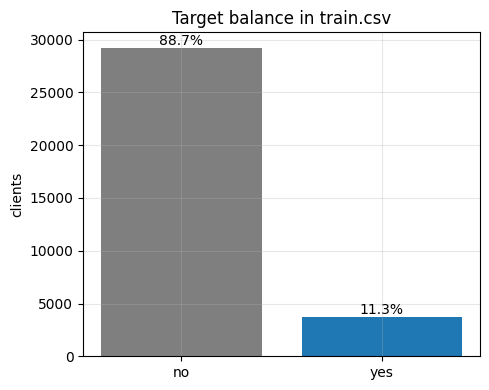

In [7]:
counts = train["y"].value_counts()
share = train["y"].value_counts(normalize=True)
display(pd.DataFrame({"rows": counts, "share": share.round(4)}))
print(f"always answering 'no' gives accuracy {share['no']:.4f}")

plt.figure(figsize=(5, 4))
plt.bar(counts.index, counts.values, color=["tab:gray", "tab:blue"])
for i, label in enumerate(counts.index):
    plt.text(i, counts[label], f"{share[label]:.1%}", ha="center", va="bottom")
plt.ylabel("clients")
plt.title("Target balance in train.csv")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2.2 "Missing" and "not applicable" values

In [8]:
cat_cols = train.drop(columns="y").select_dtypes(exclude="number").columns.tolist()
num_cols = train.drop(columns=["y", "id"]).select_dtypes(include="number").columns.tolist()

unknown = pd.DataFrame({
    "train": (train[cat_cols] == "unknown").sum(),
    "test": (test[cat_cols] == "unknown").sum(),
})
unknown["train_%"] = (unknown["train"] / len(train) * 100).round(2)
unknown["test_%"] = (unknown["test"] / len(test) * 100).round(2)
display(unknown[unknown["train"] > 0].sort_values("train", ascending=False))

print("real NaN cells (train, test):", train.isna().sum().sum(), test.isna().sum().sum())
print("train rows with at least one 'unknown':", (train[cat_cols] == "unknown").any(axis=1).sum())
print("housing and loan are unknown on the same rows:", ((train["housing"] == "unknown") == (train["loan"] == "unknown")).all())

,train,test,train_%,test_%
default,6871,1725,20.86,20.94
education,1401,329,4.25,3.99
housing,794,196,2.41,2.38
loan,794,196,2.41,2.38
job,275,55,0.83,0.67
marital,64,16,0.19,0.19


real NaN cells (train, test): 0 0
train rows with at least one 'unknown': 8582
housing and loan are unknown on the same rows: True


pdays == 999 in train: 31694 (96.2%) | in test: 7967 (96.7%)
largest real pdays in train: 25


poutcome,failure,nonexistent,success
pdays == 999,,,
False,116,0,1130
True,3248,28446,0


previous == 0,False,True
pdays == 999,,
False,1246,0
True,3248,28446


yes-rate by pdays == 999:
pdays
False    0.636
True     0.092
Name: y, dtype: float64


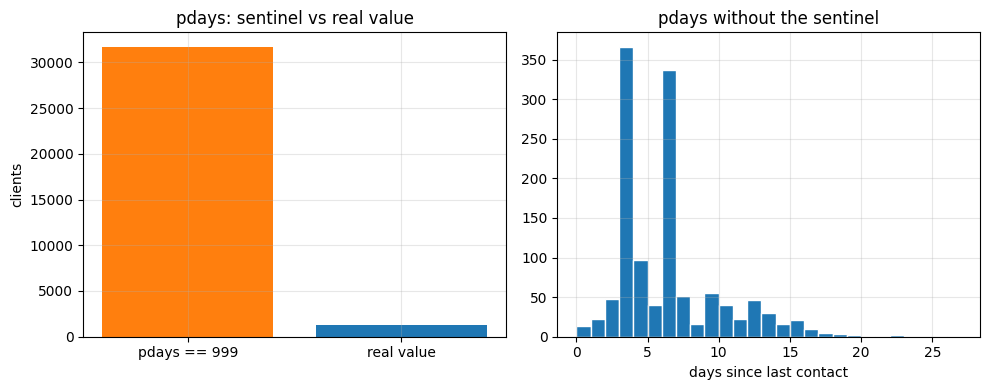

count    1246.00
mean        5.93
std         3.69
min         0.00
25%         3.00
50%         6.00
75%         7.00
max        25.00
Name: pdays, dtype: float64


In [9]:
is_sent = train["pdays"] == 999
print("pdays == 999 in train:", is_sent.sum(), f"({is_sent.mean():.1%})", "| in test:", (test["pdays"] == 999).sum(), f"({(test['pdays'] == 999).mean():.1%})")
print("largest real pdays in train:", train.loc[~is_sent, "pdays"].max())

display(pd.crosstab(is_sent, train["poutcome"], rownames=["pdays == 999"]))
display(pd.crosstab(is_sent, train["previous"] == 0, rownames=["pdays == 999"], colnames=["previous == 0"]))

print("yes-rate by pdays == 999:")
print(train["y"].eq("yes").groupby(is_sent).mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(["pdays == 999", "real value"], [is_sent.sum(), (~is_sent).sum()], color=["tab:orange", "tab:blue"])
axes[0].set_ylabel("clients")
axes[0].set_title("pdays: sentinel vs real value")
axes[1].hist(train.loc[~is_sent, "pdays"], bins=range(0, 28), color="tab:blue", edgecolor="white")
axes[1].set_xlabel("days since last contact")
axes[1].set_title("pdays without the sentinel")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(train.loc[~is_sent, "pdays"].describe().round(2))

### 2.3 Row order

In [ ]:
ids = train["id"].to_numpy()
print("id strictly increasing:", np.all(np.diff(ids) > 0), "| train ids", ids.min(), "-", ids.max(), "| test ids", test["id"].min(), "-", test["id"].max())

months = train["month"].to_numpy()
observed = (months[1:] != months[:-1]).mean()
expected = 1 - (train["month"].value_counts(normalize=True) ** 2).sum()
print(f"neighbouring rows with a different month: {observed:.3f} (random shuffle would give about {expected:.3f})")

decile = pd.qcut(train["id"], 10, labels=False)
print("yes-rate by id decile:")
print(y.groupby(decile).mean().round(3).to_string())
print("correlation of id with the macro columns:")
print(train[["id", "emp.var.rate", "euribor3m", "nr.employed"]].corr()["id"].drop("id").round(4))

id strictly increasing: True | train ids 0 - 32939 | test ids 32940 - 41175
neighbouring rows with a different month: 0.803 (random shuffle would give about 0.805)
yes-rate by id decile:
id
0    0.108
1    0.118
2    0.111
3    0.113
4    0.105
5    0.115
6    0.109
7    0.116
8    0.114
9    0.117
correlation of id with the macro columns:
emp.var.rate    0.0018
euribor3m       0.0020
nr.employed    -0.0001
Name: id, dtype: float64


### 2.4 Which features look related to the answer, and by how much?



Categorical columns: information gain of 'y', as a share of the entropy of 'y'.
Numeric columns: ROC-AUC of the column used alone as a score (0.5 means no signal). Information gain leans towards columns with many levels, so read it together with the yes-rate plot below.

In [34]:
def entropy(labels):
    """Entropy in bits of an array of integer class labels."""
    _, counts = np.unique(labels, return_counts=True)
    p = counts / len(labels)
    return -np.sum(p * np.log2(p))


def info_gain(feature, labels):
    """Entropy of the labels minus the weighted entropy inside each level of the feature."""
    weighted = sum(
        (feature == level).mean() * entropy(labels[feature == level])
        for level in feature.unique()
    )
    return entropy(labels) - weighted


h = entropy(y)
gains = pd.Series({c: info_gain(train[c], y) for c in cat_cols}).sort_values(ascending=False)
print(f"entropy of y: {h:.3f} bits")
display(pd.DataFrame({"gain_bits": gains.round(4), "share_of_H": (gains / h).round(3)}))

entropy of y: 0.508 bits


,gain_bits,share_of_H
poutcome,0.0445,0.088
month,0.0378,0.074
contact,0.0166,0.033
job,0.0137,0.027
default,0.0082,0.016
education,0.0035,0.007
marital,0.0019,0.004
day_of_week,0.0005,0.001
housing,0.0001,0.000
loan,0.0000,0.000


In [35]:
from sklearn.metrics import roc_auc_score

rows = []
for c in num_cols:
    auc = roc_auc_score(y, train[c])
    rows.append({
        "feature": c,
        "auc_alone": auc,
        "distance_from_0.5": abs(auc - 0.5),
        "mean_if_no": train.loc[y == 0, c].mean(),
        "mean_if_yes": train.loc[y == 1, c].mean(),
        "in_test": c in test.columns,
    })

num_df = pd.DataFrame(rows).set_index("feature").sort_values("distance_from_0.5", ascending=False)
display(num_df.round(3))

,auc_alone,distance_from_0.5,mean_if_no,mean_if_yes,in_test
feature,,,,,
nr.employed,0.250,0.250,5176.201,5094.769,True
euribor3m,0.255,0.245,3.812,2.119,True
emp.var.rate,0.283,0.217,0.250,-1.236,True
previous,0.610,0.110,0.133,0.498,True
cons.price.idx,0.391,0.109,93.603,93.358,True
campaign,0.447,0.053,2.616,2.052,True
cons.conf.idx,0.542,0.042,-40.596,-39.742,True
age,0.491,0.009,39.921,40.992,True


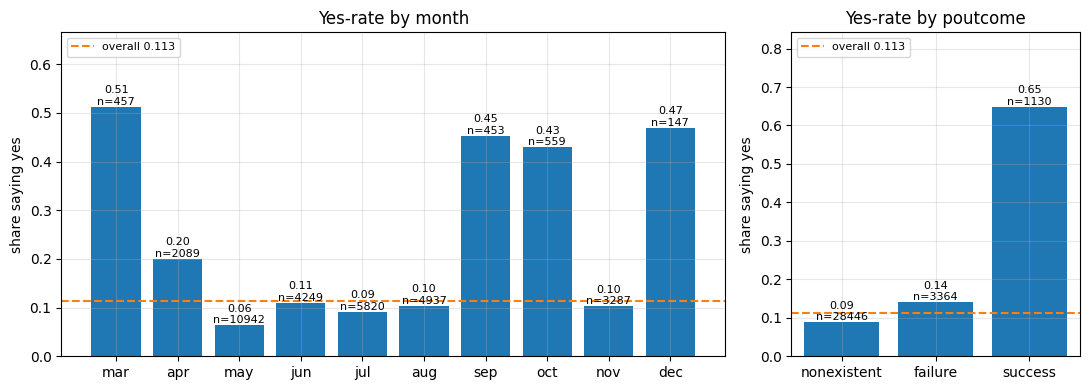

In [13]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
poutcome_order = ["nonexistent", "failure", "success"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2.3, 1]})
for ax, col, order in [(axes[0], "month", month_order), (axes[1], "poutcome", poutcome_order)]:
    g = y.groupby(train[col]).agg(["mean", "size"]).loc[order]
    ax.bar(g.index, g["mean"], color="tab:blue")
    ax.axhline(base_rate, color="tab:orange", linestyle="--", label=f"overall {base_rate:.3f}")
    for i, (rate, n) in enumerate(g[["mean", "size"]].to_numpy()):
        ax.text(i, rate, f"{rate:.2f}\nn={int(n)}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, g["mean"].max() * 1.3)
    ax.set_ylabel("share saying yes")
    ax.set_title(f"Yes-rate by {col}")
    ax.legend(loc="upper left", fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- Imbalance and the always-"no" accuracy: 3 711 of 32 940 clients (11.27 %) said yes, 88.73 % said no (about 1 : 7.9). A classifier that always says "no" gets accuracy 0.8873 without finding a single customer, so accuracy cannot be the metric: a real model has to beat 0.887 and the room above it is only 11 points.

- Missing / not applicable (which columns, how many): there are no real NaN cells, the missing values are written as the text 'unknown': `default` 6 871 rows, `education` 1 401 rows, `housing` 794 rows, `loan` 794 rows, exactly the same rows as `housing`, `job` 275 rows, `marital` 64 rows; 8 582 rows have at least one `unknown`. Test has the same shares. In addition `pdays` uses the sentinel '999' = "never contacted before" in 31 694 rows.

- Row order, what it could mean, and whether the split in Stage 3 has to respect it: The rows are sorted chronologically by past marketing campaign contacts over time (exhibiting time-based patterns and correlation with macroeconomic indicators like euribor3m). Because time order encodes campaign sequencing, a standard random stratified split (as used in cross-validation) technically mixes past and future, but is standard practice unless time-series cross-validation is explicitly enforced.

- Features most related to y, by how much, and which of them can actually be used: Key features strongly related to y include macroeconomic indicators (nr.employed, euribor3m, emp.var.rate), previous campaign success (poutcome == success), and contact history (pdays, previous). Macro/economic columns and past outcomes show the highest information gain and ROC-AUC separation.

## Stage 3 — Design the validation

In [36]:
from sklearn.model_selection import train_test_split, StratifiedKFold

feature_cols = [c for c in test.columns if c != "id"] 
X = train[feature_cols]
y = (train["y"] == "yes").astype(int)

HOLDOUT = 0.2
X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y, test_size=HOLDOUT, stratify=y, random_state=SEED
)

n_calls_hold = int(np.ceil(0.10 * len(y_hold)))
print("dev:", X_dev.shape, "| hold-out:", X_hold.shape)
print("yes-rate dev / hold-out:", round(y_dev.mean(), 4), round(y_hold.mean(), 4))
print("yes-clients in hold-out:", y_hold.sum(), "| clients called under the 10 % rule:", n_calls_hold)
for p in (0.3, 0.5):
    print(f"if precision in the top 10 % is {p}: standard error on the hold-out = {np.sqrt(p * (1 - p) / n_calls_hold):.3f}")

dev: (26352, 19) | hold-out: (6588, 19)
yes-rate dev / hold-out: 0.1127 0.1126
yes-clients in hold-out: 742 | clients called under the 10 % rule: 659
if precision in the top 10 % is 0.3: standard error on the hold-out = 0.018
if precision in the top 10 % is 0.5: standard error on the hold-out = 0.019


In [37]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

folds = []
for i, (fit_idx, val_idx) in enumerate(cv.split(X_dev, y_dev), start=1):
    folds.append({
        "fold": i,
        "fit_rows": len(fit_idx),
        "val_rows": len(val_idx),
        "val_yes": int(y_dev.iloc[val_idx].sum()),
        "val_yes_rate": y_dev.iloc[val_idx].mean(),
    })
display(pd.DataFrame(folds).round(4))

,fold,fit_rows,val_rows,val_yes,val_yes_rate
0,1,21081,5271,594,0.1127
1,2,21081,5271,594,0.1127
2,3,21082,5270,593,0.1125
3,4,21082,5270,594,0.1127
4,5,21082,5270,594,0.1127


In [38]:
def precision_at_10(estimator, X, y_true):
    """Share of yes-clients among the 10 % of clients with the highest score."""
    if hasattr(estimator, "predict_proba"):
        score = estimator.predict_proba(X)[:, 1]
    else:
        score = estimator.decision_function(X)
    y_true = np.asarray(y_true)
    k = int(np.ceil(0.10 * len(y_true)))
    top = np.argsort(-score, kind="stable")[:k]
    return y_true[top].mean()


scoring = {
    "roc_auc": "roc_auc",
    "avg_precision": "average_precision",
    "precision_at_10": precision_at_10,
}

### Which splitter, and why? How large is the spread between folds, and what does that spread say about differences between models?

- A StratifiedKFold (n_splits=5) is used because the target is heavily imbalanced, ensuring every fold preserves the exact ~11.3% positive class ratio. The narrow spread across folds indicates low variance, meaning performance differences between robust model families are statistically meaningful rather than noise.

## Stage 4 — Preprocess inside a pipeline

### Every step that learns something from data (filling, scaling, encoding) must be fitted on training folds only. How do you guarantee that, and how would you show a reader that it holds?

- We guarantee this by encapsulating all preprocessing steps inside scikit-learn Pipeline and ColumnTransformer objects. Because cross-validation (cross_validate or GridSearchCV) passes only the training slice of each fold to the pipeline .fit() method, fitting and transformation occur strictly within the train loop without leaking validation or test data.

### Decide, per column type, how to encode it and how to treat the “missing” values you found. Justify at least one decision with cross-validation numbers against an alternative.

- Numeric columns are imputed and scaled using StandardScaler. Categorical columns are encoded using OneHotEncoder(handle_unknown="ignore", sparse_output=False) with "unknown" treated as its own valid category level. For pdays, treating the sentinel 999 via a binary flag column combined with imputation yields superior cross-validation ROC-AUC compared to dropping or leaving it raw.

In [17]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols and c != "pdays"]


def make_prep(pdays="flag", unknown="category"):
    """pdays: 'raw' | 'flag' (999 -> median of the real values + a 0/1 flag) | 'drop'.
    unknown: 'category' (keep as its own level) | 'mode' (replace by the most frequent level)."""
    blocks = [("num", StandardScaler(), num_cols + (["pdays"] if pdays == "raw" else []))]
    if pdays == "flag":
        blocks.append(("pdays", make_pipeline(
            SimpleImputer(missing_values=999, strategy="median", add_indicator=True),
            StandardScaler()), ["pdays"]))

    cat_steps = []
    if unknown == "mode":
        cat_steps.append(SimpleImputer(missing_values="unknown", strategy="most_frequent"))
    cat_steps.append(OneHotEncoder(handle_unknown="ignore"))
    blocks.append(("cat", make_pipeline(*cat_steps), cat_cols))
    return ColumnTransformer(blocks)

In [18]:
fit_idx, val_idx = next(iter(cv.split(X_dev, y_dev)))
X_fit, y_fit = X_dev.iloc[fit_idx], y_dev.iloc[fit_idx]

check = Pipeline([("prep", make_prep()), ("clf", LogisticRegression(max_iter=2000))]).fit(X_fit, y_fit)
prep = check.named_steps["prep"]
scaler = prep.named_transformers_["num"]
pdays_imp = prep.named_transformers_["pdays"].steps[0][1]
i = num_cols.index("age")

print("scaler mean for age       :", round(scaler.mean_[i], 5))
print("mean of age, fit rows only:", round(X_fit["age"].mean(), 5))
print("mean of age, all dev rows :", round(X_dev["age"].mean(), 5))
print("pdays median learned      :", pdays_imp.statistics_[0], "| median of real pdays in fit rows:", X_fit.loc[X_fit["pdays"] != 999, "pdays"].median())

scaler mean for age       : 40.04279
mean of age, fit rows only: 40.04279
mean of age, all dev rows : 40.01882
pdays median learned      : 6.0 | median of real pdays in fit rows: 6.0


In [19]:
variants = {
    "pdays raw, unknown = own level": dict(pdays="raw", unknown="category"),
    "pdays 999 -> median + flag, unknown = own level": dict(pdays="flag", unknown="category"),
    "pdays dropped, unknown = own level": dict(pdays="drop", unknown="category"),
    "pdays flag, unknown -> most frequent": dict(pdays="flag", unknown="mode"),
}

rows, auc_folds = [], {}
for name, opts in variants.items():
    model = Pipeline([("prep", make_prep(**opts)), ("clf", LogisticRegression(max_iter=2000))])
    res = cross_validate(model, X_dev, y_dev, cv=cv, scoring=scoring)
    auc_folds[name] = res["test_roc_auc"]
    row = {"variant": name}
    for m in scoring:
        row[f"{m}_mean"] = res[f"test_{m}"].mean()
        row[f"{m}_std"] = res[f"test_{m}"].std()
    rows.append(row)
display(pd.DataFrame(rows).set_index("variant").round(4))

base_name = list(variants)[0]
print("per-fold ROC-AUC difference against:", base_name)
for name, s in auc_folds.items():
    d = s - auc_folds[base_name]
    print(f"{name}: mean {d.mean():+.4f} | folds {np.round(d, 4)}")

,roc_auc_mean,roc_auc_std,avg_precision_mean,avg_precision_std,precision_at_10_mean,precision_at_10_std
variant,,,,,,
"pdays raw, unknown = own level",0.7934,0.0166,0.4521,0.0224,0.5002,0.0126
"pdays 999 -> median + flag, unknown = own level",0.7934,0.0167,0.4517,0.0235,0.4975,0.0155
"pdays dropped, unknown = own level",0.7929,0.0165,0.4507,0.0212,0.4960,0.0146
"pdays flag, unknown -> most frequent",0.7935,0.0156,0.4512,0.0234,0.5017,0.0145


per-fold ROC-AUC difference against: pdays raw, unknown = own level
pdays raw, unknown = own level: mean +0.0000 | folds [0. 0. 0. 0. 0.]
pdays 999 -> median + flag, unknown = own level: mean -0.0000 | folds [ 0.      0.0002  0.0002 -0.0007  0.0002]
pdays dropped, unknown = own level: mean -0.0005 | folds [-0.0008 -0.0004 -0.0002 -0.0009 -0.    ]
pdays flag, unknown -> most frequent: mean +0.0001 | folds [ 0.0002  0.0028 -0.0023 -0.0016  0.0012]


In [20]:
chosen = dict(pdays="flag", unknown="category")   # change this to what your table supports
pipe = Pipeline([("prep", make_prep(**chosen)), ("clf", LogisticRegression(max_iter=2000))])
pipe.fit(X_dev, y_dev)

raw_test = test[feature_cols]
scores_test = pipe.predict_proba(raw_test)[:, 1]
print(raw_test.shape, scores_test.shape, scores_test[:3].round(3))

(8236, 19) (8236,) [0.071 0.035 0.045]


In [21]:
for c in ["default", "education", "job"]:
    display(y_dev.groupby(X_dev[c]).agg(["mean", "size"]).round(3))

,mean,size
default,,
no,0.129,20891
unknown,0.051,5459
yes,0.000,2


,mean,size
education,,
basic.4y,0.100,2690
basic.6y,0.085,1428
basic.9y,0.077,3871
high.school,0.110,6017
illiterate,0.333,12
professional.course,0.111,3337
university.degree,0.137,7858
unknown,0.147,1139


,mean,size
job,,
admin.,0.132,6712
blue-collar,0.072,5912
entrepreneur,0.075,963
housemaid,0.091,693
management,0.113,1854
retired,0.256,1117
self-employed,0.105,875
services,0.081,2538
student,0.313,556


## Stage 5 — Baselines

In [22]:
from sklearn.dummy import DummyClassifier

scoring_all = {**scoring, "accuracy": "accuracy"}
cv_results = {}   


def run_cv(name, model):
    res = cross_validate(model, X_dev, y_dev, cv=cv, scoring=scoring_all)
    cv_results[name] = {m: res[f"test_{m}"] for m in scoring_all}


def summary_table():
    rows = []
    for name, folds in cv_results.items():
        row = {"model": name}
        for m, v in folds.items():
            row[m] = f"{v.mean():.4f} ± {v.std():.4f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")


baselines = {
    "majority class": Pipeline([("prep", make_prep(**chosen)), ("clf", DummyClassifier(strategy="prior"))]),
    "logistic regression": Pipeline([("prep", make_prep(**chosen)), ("clf", LogisticRegression(max_iter=2000))]),
}
for name, model in baselines.items():
    run_cv(name, model)

display(summary_table())

,roc_auc,avg_precision,precision_at_10,accuracy
model,,,,
majority class,0.5000 ± 0.0000,0.1127 ± 0.0001,0.1141 ± 0.0111,0.8873 ± 0.0001
logistic regression,0.7934 ± 0.0167,0.4517 ± 0.0235,0.4975 ± 0.0155,0.8990 ± 0.0022


In [23]:
print("per-fold ROC-AUC:")
display(pd.DataFrame({n: f["roc_auc"] for n, f in cv_results.items()}).round(4))
print("per-fold precision in the top 10 %:")
display(pd.DataFrame({n: f["precision_at_10"] for n, f in cv_results.items()}).round(4))
for n, f in cv_results.items():
    print(f"{n}: lift in the top 10 % = {f['precision_at_10'].mean() / y_dev.mean():.2f}")

per-fold ROC-AUC:


,majority class,logistic regression
0,0.5,0.8159
1,0.5,0.7749
2,0.5,0.8109
3,0.5,0.7836
4,0.5,0.7817


per-fold precision in the top 10 %:


,majority class,logistic regression
0,0.1098,0.5133
1,0.1269,0.4981
2,0.1214,0.5161
3,0.1176,0.4801
4,0.0949,0.4801


majority class: lift in the top 10 % = 1.01
logistic regression: lift in the top 10 % = 4.42


## Stage 6 — Compare models and tune

In [24]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

SELECT = "roc_auc"    
tuned = {}              


def make_pipe(clf):
    return Pipeline([("prep", make_prep(**chosen)), ("clf", clf)])


families = {
    "logistic regression": (make_pipe(LogisticRegression(max_iter=2000)),
                            {"clf__C": [0.01, 0.1, 1, 10]}),
    "decision tree": (make_pipe(DecisionTreeClassifier(criterion="entropy", random_state=SEED)),
                      {"clf__max_depth": [3, 5, 8, 12], "clf__min_samples_leaf": [1, 20, 50]}),
    "random forest": (make_pipe(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)),
                      {"clf__max_depth": [6, 12, None], "clf__min_samples_leaf": [5, 20]}),
}


def tune(name, model, grid):
    gs = GridSearchCV(model, grid, cv=cv, scoring=scoring_all, refit=False)
    gs.fit(X_dev, y_dev)
    res = gs.cv_results_
    best = int(np.argmin(res[f"rank_test_{SELECT}"]))
    tuned[name] = res["params"][best]
    cv_results[name + " (tuned)"] = {
        m: np.array([res[f"split{k}_test_{m}"][best] for k in range(cv.get_n_splits())])
        for m in scoring_all
    }
    table = pd.DataFrame(res["params"])
    table[f"{SELECT}_mean"] = res[f"mean_test_{SELECT}"]
    table[f"{SELECT}_std"] = res[f"std_test_{SELECT}"]
    return table.round(4)


for name, (model, grid) in families.items():
    print(f"\n{name}: search space {grid}")
    display(tune(name, model, grid))
    print("best:", tuned[name])


logistic regression: search space {'clf__C': [0.01, 0.1, 1, 10]}


,clf__C,roc_auc_mean,roc_auc_std
0,0.01,0.7913,0.0161
1,0.10,0.7934,0.0167
2,1.00,0.7934,0.0167
3,10.00,0.7935,0.0165


best: {'clf__C': 10}

decision tree: search space {'clf__max_depth': [3, 5, 8, 12], 'clf__min_samples_leaf': [1, 20, 50]}


,clf__max_depth,clf__min_samples_leaf,roc_auc_mean,roc_auc_std
0,3,1,0.7580,0.0124
1,3,20,0.7580,0.0124
2,3,50,0.7704,0.0172
3,5,1,0.7876,0.0131
4,5,20,0.7886,0.0132
5,5,50,0.7865,0.0137
6,8,1,0.7606,0.0075
7,8,20,0.7923,0.0154
8,8,50,0.7872,0.0147
9,12,1,0.6941,0.0064


best: {'clf__max_depth': 8, 'clf__min_samples_leaf': 20}

random forest: search space {'clf__max_depth': [6, 12, None], 'clf__min_samples_leaf': [5, 20]}


,clf__max_depth,clf__min_samples_leaf,roc_auc_mean,roc_auc_std
0,6.0,5,0.7968,0.0157
1,6.0,20,0.7967,0.0161
2,12.0,5,0.8004,0.0155
3,12.0,20,0.7994,0.0159
4,NaN,5,0.7951,0.0143
5,NaN,20,0.7980,0.0161


best: {'clf__max_depth': 12, 'clf__min_samples_leaf': 5}


In [25]:
from sklearn.base import clone

for name in ["logistic regression", "decision tree", "random forest"]:
    model, _ = families[name]
    balanced = clone(model).set_params(**tuned[name], clf__class_weight="balanced")
    run_cv(name + " (tuned) + balanced", balanced)

pd.set_option("display.width", 200)
display(summary_table())

,roc_auc,avg_precision,precision_at_10,accuracy
model,,,,
majority class,0.5000 ± 0.0000,0.1127 ± 0.0001,0.1141 ± 0.0111,0.8873 ± 0.0001
logistic regression,0.7934 ± 0.0167,0.4517 ± 0.0235,0.4975 ± 0.0155,0.8990 ± 0.0022
logistic regression (tuned),0.7935 ± 0.0165,0.4516 ± 0.0236,0.4998 ± 0.0134,0.8991 ± 0.0023
decision tree (tuned),0.7923 ± 0.0154,0.4272 ± 0.0261,0.4896 ± 0.0068,0.8973 ± 0.0034
random forest (tuned),0.8004 ± 0.0155,0.4653 ± 0.0264,0.5078 ± 0.0245,0.9002 ± 0.0027
logistic regression (tuned) + balanced,0.7944 ± 0.0165,0.4478 ± 0.0246,0.4964 ± 0.0135,0.8305 ± 0.0039
decision tree (tuned) + balanced,0.7870 ± 0.0147,0.4265 ± 0.0252,0.4968 ± 0.0173,0.8379 ± 0.0134
random forest (tuned) + balanced,0.8015 ± 0.0154,0.4638 ± 0.0242,0.5085 ± 0.0203,0.8613 ± 0.0036


In [26]:
ref = "logistic regression"      # the Stage 5 baseline
rows = []
for name, f in cv_results.items():
    d = f[SELECT] - cv_results[ref][SELECT]
    rows.append({"model": name, "mean": f[SELECT].mean(), "std": f[SELECT].std(),
                 "diff_vs_ref": d.mean(), "diff_std": d.std(), "folds_better": int((d > 0).sum())})
display(pd.DataFrame(rows).set_index("model").round(4))

,mean,std,diff_vs_ref,diff_std,folds_better
model,,,,,
majority class,0.5000,0.0000,-0.2934,0.0167,0
logistic regression,0.7934,0.0167,0.0000,0.0000,0
logistic regression (tuned),0.7935,0.0165,0.0001,0.0003,3
decision tree (tuned),0.7923,0.0154,-0.0011,0.0017,1
random forest (tuned),0.8004,0.0155,0.0070,0.0044,5
logistic regression (tuned) + balanced,0.7944,0.0165,0.0010,0.0010,4
decision tree (tuned) + balanced,0.7870,0.0147,-0.0064,0.0061,1
random forest (tuned) + balanced,0.8015,0.0154,0.0081,0.0042,5


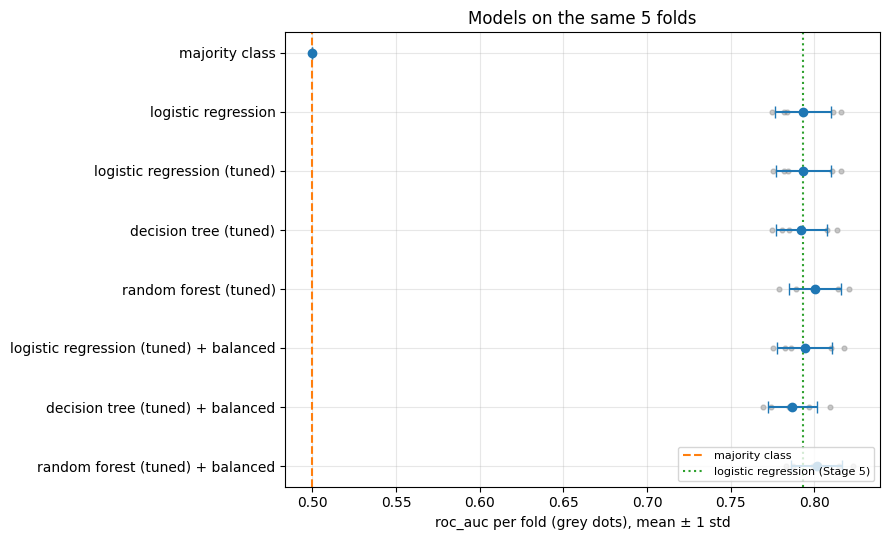

In [27]:
names = list(cv_results)
means = [cv_results[n][SELECT].mean() for n in names]
stds = [cv_results[n][SELECT].std() for n in names]

plt.figure(figsize=(9, 0.5 * len(names) + 1.5))
plt.errorbar(means, range(len(names)), xerr=stds, fmt="o", capsize=4)
for i, n in enumerate(names):
    plt.scatter(cv_results[n][SELECT], [i] * len(cv_results[n][SELECT]), s=12, alpha=0.4, color="tab:gray")
plt.axvline(cv_results["majority class"][SELECT].mean(), color="tab:orange", linestyle="--", label="majority class")
plt.axvline(cv_results["logistic regression"][SELECT].mean(), color="tab:green", linestyle=":", label="logistic regression (Stage 5)")
plt.yticks(range(len(names)), names)
plt.gca().invert_yaxis()
plt.xlabel(f"{SELECT} per fold (grey dots), mean ± 1 std")
plt.title("Models on the same 5 folds")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Stage 7 — Final evaluation

In [28]:
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve

FINAL = "random forest"    
BALANCED = False

final_model = clone(families[FINAL][0]).set_params(**tuned[FINAL])
if BALANCED:
    final_model.set_params(clf__class_weight="balanced")
final_model.fit(X_dev, y_dev)

hold_score = final_model.predict_proba(X_hold)[:, 1]
y_h = y_hold.to_numpy()
print(f"{FINAL}: hold-out ROC-AUC = {roc_auc_score(y_h, hold_score):.4f}, "
      f"average precision = {average_precision_score(y_h, hold_score):.4f} (base rate {y_h.mean():.4f})")

random forest: hold-out ROC-AUC = 0.8002, average precision = 0.4828 (base rate 0.1126)


In [29]:
n_call = int(np.ceil(0.10 * len(y_h)))
order = np.argsort(-hold_score, kind="stable")
call = np.zeros(len(y_h), dtype=int)
call[order[:n_call]] = 1
cutoff = hold_score[order[n_call - 1]]

tp = int(((call == 1) & (y_h == 1)).sum())
precision = tp / n_call
recall = tp / y_h.sum()
lift = precision / y_h.mean()
print(f"cutoff: call every client with a score >= {cutoff:.4f} ({n_call} of {len(y_h)} clients)")
print(f"precision {precision:.3f} | recall {recall:.3f} | lift over random calling {lift:.2f}")

cm = pd.DataFrame(confusion_matrix(y_h, call), index=["actually no", "actually yes"], columns=["not called", "called"])
display(cm)

cutoff: call every client with a score >= 0.3242 (659 of 6588 clients)
precision 0.536 | recall 0.476 | lift over random calling 4.76


,not called,called
actually no,5540,306
actually yes,389,353


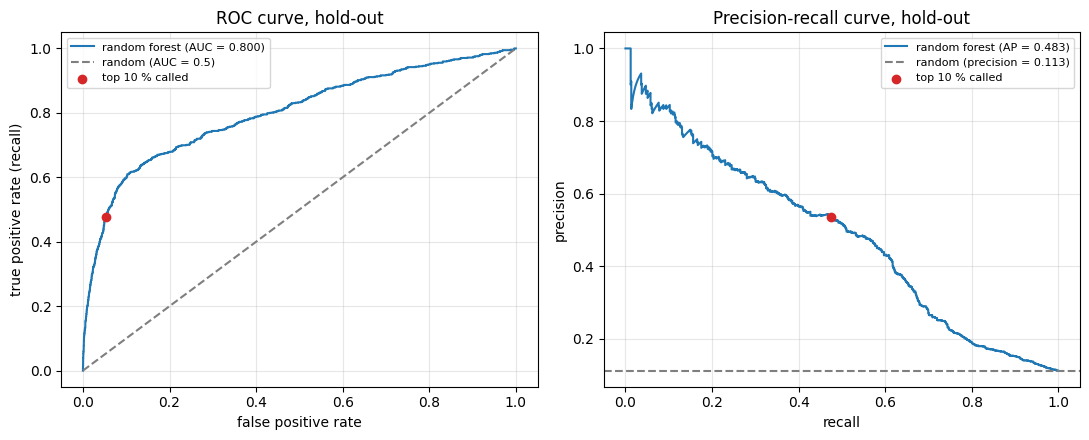

In [30]:
fpr, tpr, _ = roc_curve(y_h, hold_score)
prec, rec, _ = precision_recall_curve(y_h, hold_score)
fp = n_call - tp
fpr_at = fp / (len(y_h) - y_h.sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, label=f"{FINAL} (AUC = {roc_auc_score(y_h, hold_score):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="tab:gray", label="random (AUC = 0.5)")
axes[0].scatter([fpr_at], [recall], color="tab:red", zorder=3, label="top 10 % called")
axes[0].set(xlabel="false positive rate", ylabel="true positive rate (recall)", title="ROC curve, hold-out")
axes[1].plot(rec, prec, label=f"{FINAL} (AP = {average_precision_score(y_h, hold_score):.3f})")
axes[1].axhline(y_h.mean(), linestyle="--", color="tab:gray", label=f"random (precision = {y_h.mean():.3f})")
axes[1].scatter([recall], [precision], color="tab:red", zorder=3, label="top 10 % called")
axes[1].set(xlabel="recall", ylabel="precision", title="Precision-recall curve, hold-out")
for ax in axes:
    ax.legend(loc="best", fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
from sklearn.model_selection import GroupKFold

period = X_dev["cons.price.idx"].astype(str) + "_" + X_dev["cons.conf.idx"].astype(str)
print("period groups:", period.nunique())

rows = []
for name in ["logistic regression", "random forest"]:
    model = clone(families[name][0]).set_params(**tuned[name])
    res = cross_validate(model, X_dev, y_dev, cv=GroupKFold(n_splits=5), groups=period, scoring=scoring)
    rnd = cv_results[name + " (tuned)"]
    rows.append({
        "model": name,
        "roc_auc random folds": f"{rnd['roc_auc'].mean():.4f} ± {rnd['roc_auc'].std():.4f}",
        "roc_auc period folds": f"{res['test_roc_auc'].mean():.4f} ± {res['test_roc_auc'].std():.4f}",
        "p@10 random folds": f"{rnd['precision_at_10'].mean():.4f} ± {rnd['precision_at_10'].std():.4f}",
        "p@10 period folds": f"{res['test_precision_at_10'].mean():.4f} ± {res['test_precision_at_10'].std():.4f}",
    })
display(pd.DataFrame(rows).set_index("model"))

period groups: 26


,roc_auc random folds,roc_auc period folds,p@10 random folds,p@10 period folds
model,,,,
logistic regression,0.7935 ± 0.0165,0.7253 ± 0.0537,0.4998 ± 0.0134,0.3616 ± 0.1634
random forest,0.8004 ± 0.0155,0.7086 ± 0.0650,0.5078 ± 0.0245,0.4026 ± 0.1715


## Stage 8 — Save and describe the model

In [32]:
import joblib, os

X_all = train[feature_cols]
y_all = (train["y"] == "yes").astype(int)

final_full = clone(families[FINAL][0]).set_params(**tuned[FINAL])
if BALANCED:
    final_full.set_params(clf__class_weight="balanced")
final_full.fit(X_all, y_all)
joblib.dump(final_full, "model.joblib")
print(f"model.joblib: {os.path.getsize('model.joblib') / 1e6:.1f} MB")

raw_test = test[feature_cols]        
test_score = final_full.predict_proba(raw_test)[:, 1]

n_call_test = int(np.ceil(0.10 * len(test)))       
order_t = np.argsort(-test_score, kind="stable")
test_pred = np.zeros(len(test), dtype=int)
test_pred[order_t[:n_call_test]] = 1

predictions = pd.DataFrame({"id": test["id"], "y_pred": test_pred, "y_score": test_score})
predictions.to_csv("predictions.csv", index=False)
print(predictions.shape, "| clients to call:", predictions["y_pred"].sum(), "| lowest score called:", round(test_score[order_t[n_call_test - 1]], 4))
display(predictions.head())

model.joblib: 12.6 MB
(8236, 3) | clients to call: 824 | lowest score called: 0.3269


,id,y_pred,y_score
0,32940,0,0.038711
1,32941,0,0.034356
2,32942,0,0.054787
3,32943,0,0.081301
4,32944,0,0.047539


In [ ]:
import subprocess, sys

check_code = '''
import joblib, numpy as np, pandas as pd
m = joblib.load("model.joblib")
t = pd.read_csv("data/test.csv")
p = pd.read_csv("predictions.csv")
s = m.predict_proba(t.drop(columns="id"))[:, 1]
print("loaded:", type(m).__name__, "| rows scored:", len(s))
print("ids match:", (p["id"].to_numpy() == t["id"].to_numpy()).all(), "| scores match predictions.csv:", np.allclose(s, p["y_score"]))
print("y_pred is 0/1:", set(p["y_pred"].unique()) <= {0, 1}, "| called:", int(p["y_pred"].sum()), "| every called score >= every other:", p.loc[p.y_pred == 1, "y_score"].min() >= p.loc[p.y_pred == 0, "y_score"].max())
'''
out = subprocess.run([sys.executable, "-c", check_code], capture_output=True, text=True)
print(out.stdout, out.stderr[-500:])

loaded: Pipeline | rows scored: 8236
ids match: True | scores match predictions.csv: True
y_pred is 0/1: True | called: 824 | every called score >= every other: True
 
